In [1]:
%pip install scikit-learn joblib matplotlib seaborn
import os, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix

os.makedirs("../report/figures", exist_ok=True)
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
tr, val = train_test_split(train, test_size=0.2, stratify=train["label"], random_state=42)
LABELS = ["safe", "email", "phone", "url_internal", "credential"]

def make_features():
    return FeatureUnion([
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                                 sublinear_tf=True, lowercase=False, max_features=50000)),
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                                 sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
    ])
print(tr.shape, val.shape, test.shape)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


(10931, 3) (2733, 3) (3416, 3)


In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
searches = {
    "LinearSVM": (LinearSVC(), {"clf__C": [0.1, 0.3, 1, 3, 10],
                                "clf__class_weight": [None, "balanced"]}),
    "LogReg":    (LogisticRegression(max_iter=3000), {"clf__C": [1, 3, 10, 30],
                                "clf__class_weight": [None, "balanced"]}),
}
tuned = {}
for name, (clf, grid) in searches.items():
    t0 = time.time()
    pipe = Pipeline([("feats", make_features()), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(tr["text"], tr["label"])
    tuned[name] = gs.best_estimator_
    print(f"{name}: best params = {gs.best_params_}")
    print(f"   CV macro F1 = {gs.best_score_:.4f}  ({time.time()-t0:.0f}s)")

LinearSVM: best params = {'clf__C': 3, 'clf__class_weight': 'balanced'}
   CV macro F1 = 0.9912  (20s)
LogReg: best params = {'clf__C': 30, 'clf__class_weight': 'balanced'}
   CV macro F1 = 0.9905  (32s)


In [3]:
svm_c = tuned["LinearSVM"].named_steps["clf"]
lr_c = tuned["LogReg"].named_steps["clf"]

voter = Pipeline([
    ("feats", make_features()),
    ("clf", VotingClassifier([
        ("svm", clone(svm_c)),
        ("lr", clone(lr_c)),
        ("rf", RandomForestClassifier(n_estimators=150, class_weight="balanced",
                                      n_jobs=-1, random_state=42)),
    ], voting="hard")),
])
voter.fit(tr["text"], tr["label"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feats', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['credential','email','phone','safe','url_internal']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('char', ...), ('word', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [4]:
default_svm = Pipeline([("feats", make_features()), ("clf", LinearSVC())]).fit(tr["text"], tr["label"])
candidates = {
    "LinearSVM (default)": default_svm,
    "LinearSVM (tuned)": tuned["LinearSVM"],
    "LogReg (tuned)": tuned["LogReg"],
    "Voting ensemble": voter,
}
rows = []
for name, m in candidates.items():
    p = m.predict(val["text"])
    rows.append({"model": name,
                 "accuracy": round((p == val["label"]).mean(), 4),
                 "macro_F1": round(f1_score(val["label"], p, average="macro"), 4),
                 "F1_credential": round(f1_score(val["label"], p, labels=["credential"], average="macro"), 3)})
cmp_df = pd.DataFrame(rows).sort_values("macro_F1", ascending=False)
cmp_df.to_csv("../report/tuning_ensemble_validation.csv", index=False)
cmp_df

,model,accuracy,macro_F1,F1_credential
3,Voting ensemble,0.9927,0.9922,0.979
2,LogReg (tuned),0.9927,0.9921,0.979
1,LinearSVM (tuned),0.9930,0.9919,0.981
0,LinearSVM (default),0.9927,0.9916,0.980


Chosen model: Voting ensemble
              precision    recall  f1-score   support

        safe      0.994     0.998     0.996      1724
       email      1.000     1.000     1.000       500
       phone      0.996     0.996     0.996       500
url_internal      1.000     1.000     1.000       152
  credential      0.992     0.980     0.986       540

    accuracy                          0.995      3416
   macro avg      0.997     0.995     0.996      3416
weighted avg      0.995     0.995     0.995      3416

Test macro F1: 0.9957


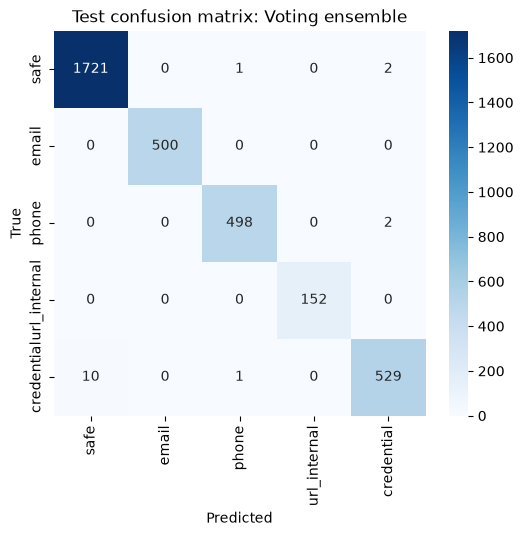

In [5]:
best_name = cmp_df.iloc[0]["model"]
print("Chosen model:", best_name)

final = clone(candidates[best_name])
final.fit(train["text"], train["label"])        # refit on ALL training data
pred = final.predict(test["text"])

print(classification_report(test["label"], pred, labels=LABELS, digits=3))
print("Test macro F1:", round(f1_score(test["label"], pred, average="macro"), 4))

cm = confusion_matrix(test["label"], pred, labels=LABELS)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Test confusion matrix: {best_name}")
plt.savefig("../report/figures/confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

              Regex F1  ML F1
safe             0.947  0.996
email            1.000  1.000
phone            0.984  0.996
url_internal     1.000  1.000
credential       0.773  0.986
macro avg        0.941  0.996


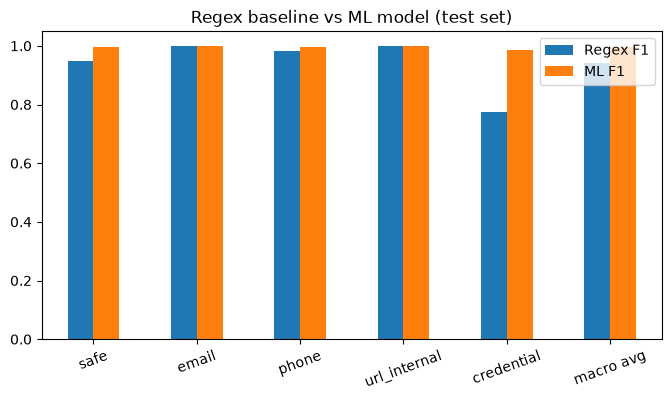

In [6]:
rep = pd.read_csv("../report/regex_baseline_results.csv", index_col=0)
ml_f1 = pd.Series(f1_score(test["label"], pred, labels=LABELS, average=None), index=LABELS)
comp = pd.DataFrame({"Regex F1": rep.loc[LABELS, "f1-score"], "ML F1": ml_f1})
comp.loc["macro avg"] = [rep.loc["macro avg", "f1-score"],
                         f1_score(test["label"], pred, average="macro")]
comp = comp.round(3)
comp.to_csv("../report/ml_vs_regex_test.csv")
print(comp)

comp.plot(kind="bar", figsize=(8, 4))
plt.title("Regex baseline vs ML model (test set)")
plt.ylim(0, 1.05); plt.xticks(rotation=20)
plt.savefig("../report/figures/ml_vs_regex.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
t = test.copy(); t["pred"] = pred
for src, g in t.groupby("source"):
    print(f"{src:18s} accuracy = {(g['label'] == g['pred']).mean():.3f}  (n={len(g)})")

errs = t[t["label"] != t["pred"]]
print(len(errs), "errors out of", len(t))
display(errs[["text", "label", "pred", "source"]].head(15))

os.makedirs("../src", exist_ok=True)
joblib.dump(final, "../src/leaklens_model.joblib")
print("model size (MB):", round(os.path.getsize("../src/leaklens_model.joblib") / 1e6, 1))

ag_news            accuracy = 0.993  (n=277)
ai4privacy         accuracy = 0.986  (n=928)
faker_synthetic    accuracy = 0.999  (n=1664)
rotten_tomatoes    accuracy = 1.000  (n=539)
ui_code            accuracy = 1.000  (n=8)
16 errors out of 3416


,text,label,pred,source
131,information such as Dennis's h4yW2I4iydWh shou...,credential,safe,ai4privacy
319,or pFH4JczcDi5c over communications.,credential,safe,ai4privacy
559,Check your email inbox,safe,credential,faker_synthetic
656,South Ethelynfield and FCLRecSgd5os?,credential,safe,ai4privacy
928,you retrieve Mariela_Von19's mIAm5yK1Cvuc?,credential,safe,ai4privacy
950,look? Use the secure line 0201 81530749 to con...,phone,credential,ai4privacy
1129,"Kamron44, your telemedicine jecppWG1ZGTa expir...",credential,safe,ai4privacy
1308,"immediate effect, I suggest xlOi4Us4N4ja. Note...",credential,safe,ai4privacy
1375,usr/pass: 146 88 1368/CnZKzkn8KOnr. Follow ins...,credential,safe,ai4privacy
1560,SBWFSLL6XXX. Passphrase '203unTuOykL2'.,credential,safe,ai4privacy


model size (MB): 35.1


In [8]:
lr_final = clone(tuned["LogReg"])
lr_final.fit(train["text"], train["label"])        # refit on all training data
pred_lr = lr_final.predict(test["text"])
print("LogReg test macro F1:", round(f1_score(test["label"], pred_lr, average="macro"), 4))

joblib.dump(lr_final, "../src/leaklens_logreg.joblib")
print("size (MB):", round(os.path.getsize("../src/leaklens_logreg.joblib") / 1e6, 1))

# quick check that probabilities work
print(lr_final.predict_proba(["password=Xk9mP2qLw8", "Meeting at 3 pm"]).round(3))
print(lr_final.classes_)

LogReg test macro F1: 0.9956
size (MB): 4.6
[[1.    0.    0.    0.    0.   ]
 [0.003 0.    0.001 0.996 0.   ]]
['credential' 'email' 'phone' 'safe' 'url_internal']


# 07 - Tuning, Ensemble and Final Test Evaluation

## Purpose
Improve the models with hyperparameter tuning and a voting ensemble, choose the best model
on the validation set, then evaluate it once on the untouched test set and compare it with
the regex baseline.

## Input / Output
- **Input:** `data/train.csv`, `data/test.csv`, `report/regex_baseline_results.csv`
- **Output:** `report/tuning_ensemble_validation.csv`, `report/ml_vs_regex_test.csv`,
  `report/figures/confusion_matrix_test.png`, `report/figures/ml_vs_regex.png`,
  `src/leaklens_model.joblib`, `src/leaklens_logreg.joblib`

## What we did
1. Used GridSearchCV with 5-fold stratified cross-validation (scoring: macro F1) to tune
   Linear SVM and Logistic Regression (C value and class weights).
2. Built a hard-voting ensemble of tuned SVM, tuned Logistic Regression and Random Forest.
3. Compared the default SVM, tuned SVM, tuned Logistic Regression and the ensemble on the
   validation set.
4. Refit the best model on the full training set and evaluated it once on the test set.
5. Compared per-class F1 against the regex baseline and read the remaining errors.
6. Saved the ensemble, and also the tuned Logistic Regression for the app, because it
   outputs probabilities and is small.

## Results
| Model (validation) | Accuracy | Macro F1 |
|---|---|---|
| Voting ensemble | 0.9927 | 0.9922 |
| LogReg (tuned) | 0.9927 | 0.9921 |
| LinearSVM (tuned) | 0.9930 | 0.9919 |
| LinearSVM (default) | 0.9927 | 0.9916 |

- Best parameters: SVM ___, LogReg ___ (copy from the printout in Cell 2)
- Tuning and ensembling improved macro F1 by only about 0.0006 over the default SVM.
- Final test macro F1: 0.996, compared with 0.941 for the regex baseline.

| Class | Regex F1 | ML F1 |
|---|---|---|
| safe | 0.947 | 0.996 |
| email | 1.000 | 1.000 |
| phone | 0.984 | 0.996 |
| url_internal | 1.000 | 1.000 |
| credential | 0.773 | 0.986 |

- Biggest gain: credential, from 0.773 to 0.986. Regex cannot detect random-looking
  secrets without a keyword, and ML can.
- Regex was already perfect on email and url_internal, because those have fixed formats.
- Per-source test accuracy: ___ (from Cell 7)
- Main remaining errors: ___ (from Cell 7)

## Key concepts learned
- **GridSearchCV** tries every parameter combination and scores each with cross-validation,
  so the choice does not depend on one lucky split.
- **Voting ensemble:** several models vote and the majority label wins.
- **Test set discipline:** the test set is used once, only for the final score.
- **Baseline comparison** shows where machine learning adds real value over fixed rules.
- A model that outputs **probabilities** is needed when the app shows a confidence or
  risk score.
- **Final model for the app:** tuned Logistic Regression, test macro F1 0.9956, file size 4.6 MB
  (`src/leaklens_logreg.joblib`). It was chosen over the ensemble because the scores are
  almost identical and it outputs probabilities for the risk score.  

## Brief requirement covered
Performance improvement (tuning and ensembling), evaluation with appropriate metrics,
comparison of solution strategies (CA 2 and CA 3).

## Limitations to mention in the report
- Scores on synthetic data may be higher than on OCR text from real screenshots.
- The regex rules were written knowing our data's patterns, which favors regex.
- Tuning and the ensemble gave very small gains, so the data mattered more than the model.